# 02. 판단 · 경로계획 — 스플라인 경로 & 조향각

`path_planner_node.py` 의 경로 생성 로직과 `decision_making_function_lib.py` 의 조향각 계산을 사용합니다.

배울 내용:
1. **CubicSpline 경로 생성** — 차선 타겟점들을 부드러운 곡선으로 연결
2. **조향각(기울기) 계산** — `calculate_slope_between_points`
3. **조향 명령 결정** — `motion_planner_node` 의 실제 판단 규칙 재현


## 공통 설정 실행
아래 셀은 **모든 노트북 맨 위에서 한 번 실행**합니다. 프로젝트 루트를 찾고, 실제 코드가 있는 `lib` 폴더들을 import 경로에 등록하며, 이미지 표시 헬퍼(`show`, `show_row`)를 정의합니다.


In [1]:
# === 공통 설정: 프로젝트 루트 찾기 + 라이브러리 경로 등록 ===
import sys, math
from pathlib import Path
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as _fm

# 그래프 한글 라벨이 깨지지 않도록 한글 폰트 지정 (Windows=맑은고딕 / Linux=나눔고딕)
for _f in [r'C:\Windows\Fonts\malgun.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    try:
        _fm.fontManager.addfont(_f)
        matplotlib.rcParams['font.family'] = _fm.FontProperties(fname=_f).get_name()
        break
    except Exception:
        pass
matplotlib.rcParams['axes.unicode_minus'] = False

def find_root(start):
    p = Path(start).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'src' / 'camera_perception_pkg').exists():
            return cand
    raise RuntimeError('ros3_ws 루트를 찾지 못했습니다. 노트북을 education_notebooks/ 안에서 실행하세요.')

ROOT = find_root(Path.cwd())
print('프로젝트 루트:', ROOT)

# 각 패키지의 lib 경로를 import 경로에 등록
CAM_LIB   = ROOT/'src'/'camera_perception_pkg'/'camera_perception_pkg'/'lib'
LIDAR_LIB = ROOT/'src'/'lidar_perception_pkg'/'lidar_perception_pkg'/'lib'
DEC_LIB   = ROOT/'src'/'decision_making_pkg'/'decision_making_pkg'/'lib'
SER_LIB   = ROOT/'src'/'serial_communication_pkg'/'serial_communication_pkg'/'lib'
SAMPLES   = CAM_LIB/'Collected_Datasets'/'sample_dataset'
for p in (CAM_LIB, LIDAR_LIB, DEC_LIB, SER_LIB):
    sys.path.insert(0, str(p))

# Jupyter/터미널 어디서든 이미지를 인라인으로 보기 위한 헬퍼
def show(img, title='', cmap=None, figsize=(6,4)):
    plt.figure(figsize=figsize)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV는 BGR, matplotlib은 RGB
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title); plt.axis('off'); plt.tight_layout(); plt.show()

def show_row(imgs, titles=None, cmap=None, figsize=(14,4)):
    n = len(imgs); titles = titles or ['']*n
    plt.figure(figsize=figsize)
    for i,(im,t) in enumerate(zip(imgs, titles)):
        ax = plt.subplot(1, n, i+1)
        if im.ndim == 3: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: ax.imshow(im, cmap=cmap or 'gray')
        ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


프로젝트 루트: C:\Users\asus\Documents\workspace\ros3_ws
OpenCV 5.0.0 | NumPy 2.4.6


## 실제 라이브러리 불러오기
`decision_making_function_lib.py` 를 그대로 import 합니다. (배너 출력 = 실제 코드)


In [2]:
import decision_making_function_lib as dm
from scipy.interpolate import CubicSpline



 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) |  / __/ 
|_| \_\ \___/ |____/  |_____|
                             
    _            _                 
   / \    _   _ | |_   ___         
  / _ \  | | | || __| / _ \  _____ 
 / ___ \ | |_| || |_ | (_) ||_____|
/_/   \_\ \__,_| \__| \___/        
                                   
__     __       _      _        _       
\ \   / /  ___ | |__  (_)  ___ | |  ___ 
 \ \ / /  / _ \| '_ \ | | / __|| | / _   \ V /  |  __/| | | || || (__ | ||  __/
   \_/    \___||_| |_||_| \___||_| \___|  


ROS2 기반 자율주행 설계 및 구현
Sungkyunkwan University Automation Lab.
------------------Authors------------------
Hyeong-Keun Hong <whaihong@g.skku.edu>
Jinsun Lee <with23skku@g.skku.edu>
Siwoo Lee <edenlee@g.skku.edu>
Jae-Wook Jeon <jwjeon@skku.edu>
------------------------------------------


## 1) 타겟점으로부터 경로 생성 (CubicSpline)
`path_planner_node.plan_path()` 와 **동일한 방식**입니다:
1. 차선 중심 타겟점 여러 개 + 차량 앞범퍼 중심점(`CAR_CENTER_POINT`)을 모은다
2. y(세로) 기준 정렬 후 `CubicSpline` 으로 보간
3. 100개의 촘촘한 점으로 부드러운 경로를 만든다

> 좌표계: 이미지 좌표(원점=좌상단, y는 아래로 증가). 차량은 이미지 아래쪽(y가 큰 곳)에 있습니다.


생성된 경로 점 개수: 100


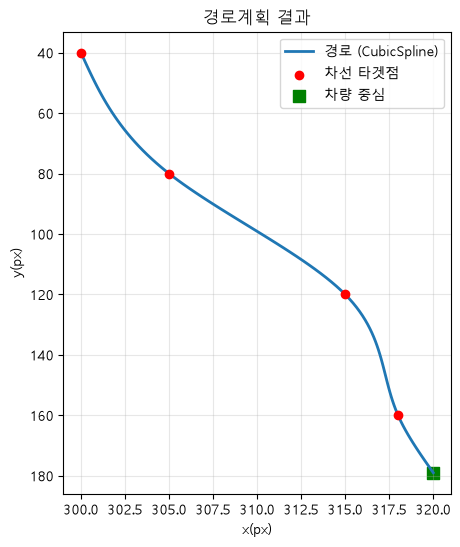

In [3]:
CAR_CENTER_POINT = (320, 179)   # path_planner_node.py 의 실제 값 (앞범퍼 중심 픽셀)

# 예시 차선 타겟점 (x, y) — YOLO/lane_extractor가 준다고 가정
target_points = [(300, 40), (305, 80), (315, 120), (318, 160)]

def plan_path(target_points, car_center=CAR_CENTER_POINT):
    xs = [p[0] for p in target_points] + [car_center[0]]
    ys = [p[1] for p in target_points] + [car_center[1]]
    pts = sorted(zip(ys, xs), key=lambda p: p[0])   # y 기준 정렬
    ys, xs = zip(*pts)
    cs = CubicSpline(ys, xs, bc_type='natural')
    y_new = np.linspace(min(ys), max(ys), 100)
    x_new = cs(y_new)
    return list(x_new), list(y_new)

x_path, y_path = plan_path(target_points)
print('생성된 경로 점 개수:', len(x_path))

plt.figure(figsize=(5,6))
tx=[p[0] for p in target_points]; ty=[p[1] for p in target_points]
plt.plot(x_path, y_path, '-', lw=2, label='경로 (CubicSpline)')
plt.scatter(tx, ty, c='red', zorder=5, label='차선 타겟점')
plt.scatter([CAR_CENTER_POINT[0]],[CAR_CENTER_POINT[1]], c='green', marker='s', s=80, label='차량 중심')
plt.gca().invert_yaxis(); plt.legend(); plt.title('경로계획 결과'); plt.xlabel('x(px)'); plt.ylabel('y(px)')
plt.grid(alpha=.3); plt.show()


## 2) 조향각 계산 — `calculate_slope_between_points`
두 점 사이의 각도를 구합니다. `motion_planner_node` 는 **경로의 끝 10번째 점과 마지막 점** 사이 기울기로
좌/우 조향을 결정합니다.

```python
# decision_making_function_lib.py 원본
def calculate_slope_between_points(p1, p2):
    if p1_y == p2_y: slope = 'inf'
    else: slope = arctan((p2_x-p1_x)/(p1_y-p2_y)) * 180/pi
    return slope
```


In [4]:
path = list(zip(x_path, y_path))
p1, p2 = path[-10], path[-1]          # motion_planner_node 와 동일
slope = dm.calculate_slope_between_points(p1, p2)
print(f'경로 끝부분 기울기: {slope:.2f}도')


경로 끝부분 기울기: -6.49도


## 3) 조향 명령 결정 (motion_planner 규칙 재현)
`motion_planner_node.timer_callback()` 의 실제 규칙:
- `target_slope > 0` → 오른쪽 조향 `+7` (최대)
- `target_slope < 0` → 왼쪽 조향 `-7`
- `= 0` → 직진 `0`
- 기본 속도: 좌/우 100 (최대 255)


In [5]:
def decide_steering(path):
    if path is None or len(path) < 10:
        return 0
    s = dm.calculate_slope_between_points(path[-10], path[-1])
    if s == 'inf': return 0
    return 7 if s > 0 else (-7 if s < 0 else 0)

steer = decide_steering(path)
print(f'조향 명령: {steer}  (좌속도=100, 우속도=100)')
print('=> ', '오른쪽' if steer>0 else '왼쪽' if steer<0 else '직진')


조향 명령: -7  (좌속도=100, 우속도=100)
=>  왼쪽


---
## 🎯 미션 1 — 커브 경로 만들기
타겟점을 오른쪽으로 휘도록 바꾸면 조향 명령이 어떻게 나올까요?
`# TODO` 의 타겟점을 수정하고, 경로/조향을 확인하세요.


조향: -7


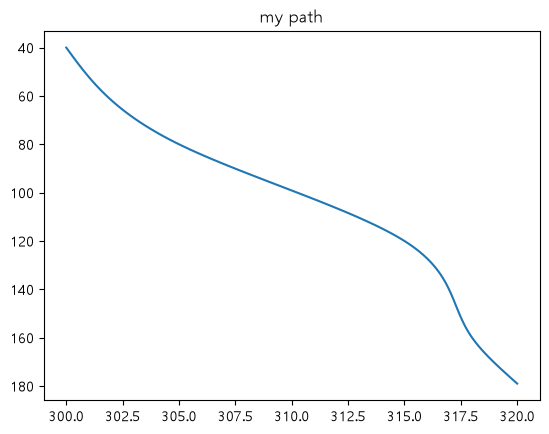

In [6]:
# TODO: 오른쪽(또는 왼쪽)으로 휘는 타겟점으로 바꿔보세요
my_targets = [(300,40), (305,80), (315,120), (318,160)]
xp, yp = plan_path(my_targets)
print('조향:', decide_steering(list(zip(xp,yp))))
plt.plot(xp,yp); plt.gca().invert_yaxis(); plt.title('my path'); plt.show()


**▶ 정답 예시** — x가 점점 커지는 타겟점을 주면 경로가 오른쪽으로 휘고 조향이 `+7` 이 됩니다.


In [7]:
right_curve = [(300,40),(330,80),(370,120),(410,160)]
left_curve  = [(340,40),(300,80),(250,120),(210,160)]
for name, tg in [('오른쪽 커브', right_curve), ('왼쪽 커브', left_curve)]:
    xp, yp = plan_path(tg)
    print(f'{name}: 조향 =', decide_steering(list(zip(xp,yp))))


오른쪽 커브: 조향 = 7
왼쪽 커브: 조향 = -7


## 🎯 미션 2 — 조향 민감도 바꾸기
현재는 기울기 부호만 보고 ±7 로 정하지만, **기울기 크기에 비례**하도록 바꾸면 더 부드럽습니다.
`decide_steering_proportional` 을 완성하세요. (최대 ±7 로 제한)


In [8]:
def decide_steering_proportional(path, gain=0.3, max_steer=7):
    s = dm.calculate_slope_between_points(path[-10], path[-1])
    if s == 'inf': return 0
    # TODO: s * gain 을 정수 조향값으로, 단 -max_steer ~ +max_steer 로 제한
    ...

# print(decide_steering_proportional(path))


**▶ 정답 예시**


In [9]:
def decide_steering_proportional(path, gain=0.3, max_steer=7):
    s = dm.calculate_slope_between_points(path[-10], path[-1])
    if s == 'inf': return 0
    val = int(round(s * gain))
    return max(-max_steer, min(max_steer, val))

for tg in [right_curve, left_curve, target_points]:
    p = list(zip(*plan_path(tg)))
    print('비례 조향:', decide_steering_proportional(p))


비례 조향: 7
비례 조향: -7
비례 조향: -2


---
✅ 판단·경로계획 완료! 다음은 **`03_라이다인지.ipynb`** 입니다.
